<a href="https://colab.research.google.com/github/WellingtonRoque/MineracaoDados/blob/main/atividades/aula9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Aula 09 — Amostragem e Balanceamento de Classes

🎯 Como selecionar dados e lidar com classes desbalanceadas

4. Preparando o ambiente

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

np.random.seed(42)

print("Ambiente preparado!")

Ambiente preparado!


🏭 5. Criando uma base industrial
Vamos criar uma base simulando leituras de motores.

Teremos:

temperatura;

vibração;

corrente;

tensão;

RPM;

falha.

A variável falha será nosso rótulo (target).

In [7]:
n = 1000

df = pd.DataFrame({
    "temperatura": np.random.normal(65, 8, n),
    "vibracao": np.random.normal(2.2, 0.7, n),
    "corrente": np.random.normal(13, 2, n),
    "tensao": np.random.normal(380, 4, n),
    "rpm": np.random.normal(1740, 15, n)
})

# Criando um cenário em que poucos registros representam falha
df["falha"] = 0

indices_falha = df[
    (df["temperatura"] > 70) &
    (df["vibracao"] > 2)
].index

df.loc[indices_falha, "falha"] = 1

df.head()

,temperatura,vibracao,corrente,tensao,rpm,falha
0,63.852614,2.815515,12.320358,381.287341,1743.976606,0
1,64.738753,2.227516,13.364270,376.874569,1733.092149,0
2,65.514359,1.561372,15.719544,382.765426,1734.927199,0
3,72.574892,1.876251,12.910582,377.638553,1731.359622,0
4,59.022262,2.439997,11.227775,382.998220,1768.758893,0


Vamos verificar quantas falhas foram geradas.

In [8]:
df["falha"].value_counts()

,count
falha,
0,822
1,178


Dependendo da distribuição aleatória, a quantidade pode variar.

Vamos visualizar.

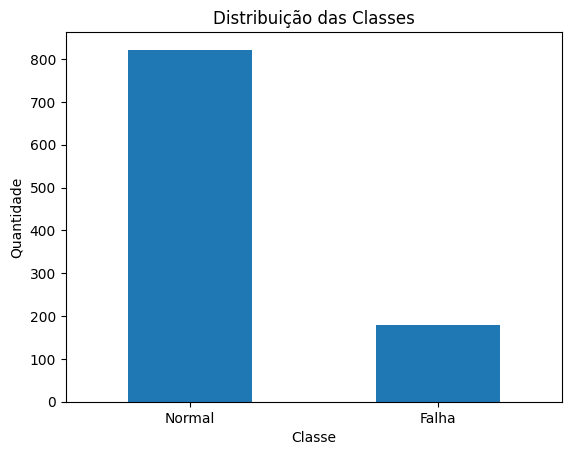

In [9]:
df["falha"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribuição das Classes")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.xticks([0, 1], ["Normal", "Falha"], rotation=0)
plt.show()

6. Identificando o desbalanceamento

Vamos calcular a porcentagem de cada classe.

In [10]:
proporcao = df["falha"].value_counts(normalize=True) * 100
proporcao

,proportion
falha,
0,82.2
1,17.8


🎯 7. Amostragem aleatória

O Pandas permite selecionar uma amostra utilizando sample().

In [11]:
amostra = df.sample(n=100, random_state=42)

amostra.shape

(100, 6)

Podemos também selecionar uma porcentagem da base.


In [12]:
amostra_20 = df.sample(frac=0.20, random_state=42)

amostra_20.shape

(200, 6)

🔬 8. Amostragem estratificada

Um problema da amostragem aleatória é que podemos selecionar uma amostra com uma proporção diferente de classes.

Quando existe uma variável importante, podemos utilizar amostragem estratificada.

Vamos utilizar a variável falha.

In [13]:
amostra_estratificada, _ = train_test_split(
    df,
    test_size=0.80,
    stratify=df["falha"],
    random_state=42
)

print("Base original:")
print(df["falha"].value_counts(normalize=True))

print("\nAmostra estratificada:")
print(amostra_estratificada["falha"].value_counts(normalize=True))

Base original:
falha
0    0.822
1    0.178
Name: proportion, dtype: float64

Amostra estratificada:
falha
0    0.82
1    0.18
Name: proportion, dtype: float64


✂️ 9. Divisão entre treino e teste
Antes de criar um modelo, normalmente dividimos os dados em:

Treinamento → utilizado para aprender

Teste       → utilizado para avaliar

Exemplo:

80% → treino

20% → teste

In [14]:
X = df.drop("falha", axis=1)
y = df["falha"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)

Treino: (800, 5)
Teste: (200, 5)


In [15]:
print("Treino:")
print(y_treino.value_counts(normalize=True))

print("\nTeste:")
print(y_teste.value_counts(normalize=True))

Treino:
falha
0    0.8225
1    0.1775
Name: proportion, dtype: float64

Teste:
falha
0    0.82
1    0.18
Name: proportion, dtype: float64


✂️ 11. Undersampling

Vamos trabalhar somente com o conjunto de treinamento.

Primeiro vamos separar as classes.

In [16]:
treino = X_treino.copy()
treino["falha"] = y_treino.values

classe_maioria = treino[treino["falha"] == 0]
classe_minoria = treino[treino["falha"] == 1]

print("Maioria:", len(classe_maioria))
print("Minoria:", len(classe_minoria))

Maioria: 658
Minoria: 142


Vamos reduzir a classe majoritária para o mesmo tamanho da minoritária.

In [17]:
classe_maioria_reduzida = classe_maioria.sample(
    n=len(classe_minoria),
    random_state=42
)

treino_under = pd.concat([
    classe_maioria_reduzida,
    classe_minoria
]).sample(frac=1, random_state=42)

treino_under["falha"].value_counts()

,count
falha,
0,142
1,142


Visualizando o resultado:

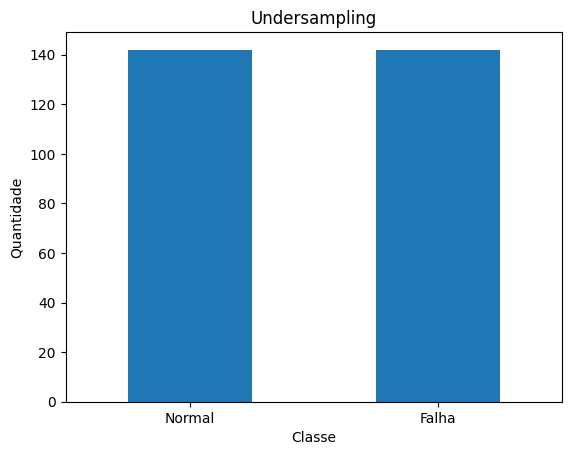

In [18]:
treino_under["falha"].value_counts().sort_index().plot(kind="bar")
plt.title("Undersampling")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.xticks([0, 1], ["Normal", "Falha"], rotation=0)
plt.show()

➕ 12. Oversampling

Agora vamos fazer o contrário.

Vamos aumentar a classe minoritária.

Uma forma simples é utilizar amostragem com reposição (replace=True).

In [19]:
classe_minoria_aumentada = classe_minoria.sample(
    n=len(classe_maioria),
    replace=True,
    random_state=42
)

treino_over = pd.concat([
    classe_maioria,
    classe_minoria_aumentada
]).sample(frac=1, random_state=42)

treino_over["falha"].value_counts()

,count
falha,
0,658
1,658


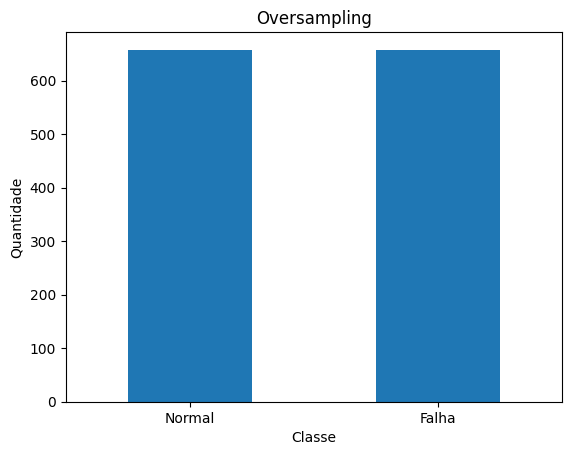

In [20]:

treino_over["falha"].value_counts().sort_index().plot(kind="bar")
plt.title("Oversampling")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.xticks([0, 1], ["Normal", "Falha"], rotation=0)
plt.show()

🧬 13. Oversampling sintético — SMOTE

Existe uma técnica bastante utilizada chamada SMOTE — Synthetic Minority Over-sampling Technique.

Em vez de simplesmente duplicar registros, ela cria novos exemplos sintéticos baseados em exemplos existentes da classe minoritária.

Vamos utilizar a implementação disponível no imbalanced-learn.

In [21]:
!pip -q install imbalanced-learn

In [22]:
from imblearn.over_sampling import SMOTE

Vamos aplicar SMOTE somente ao conjunto de treinamento.

In [23]:

smote = SMOTE(random_state=42)

X_treino_smote, y_treino_smote = smote.fit_resample(
    X_treino,
    y_treino
)

print("Antes:")
print(y_treino.value_counts())

print("\nDepois:")
print(pd.Series(y_treino_smote).value_counts())

Antes:
falha
0    658
1    142
Name: count, dtype: int64

Depois:
falha
0    658
1    658
Name: count, dtype: int64


🔍 14. Comparando as técnicas

Vamos comparar:

Original

Undersampling

Oversampling

SMOTE

In [24]:

comparacao = pd.DataFrame({
    "Original": y_treino.value_counts(),
    "Undersampling": treino_under["falha"].value_counts(),
    "Oversampling": treino_over["falha"].value_counts(),
    "SMOTE": pd.Series(y_treino_smote).value_counts()
}).fillna(0).astype(int)

comparacao

,Original,Undersampling,Oversampling,SMOTE
falha,,,,
0,658,142,658,658
1,142,142,658,658


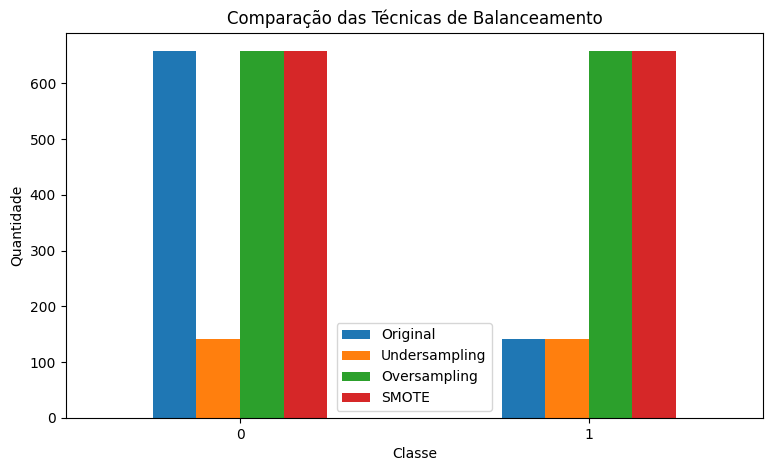

In [25]:
comparacao.plot(kind="bar", figsize=(9, 5))
plt.title("Comparação das Técnicas de Balanceamento")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.xticks(rotation=0)
plt.show()